# 04 · Calibración de falsos positivos y límites

Si no hubiera señal, ¿cuántas veces dirían "significativo" nuestras pruebas? Se mide con sustitutos nulos que conservan la autocorrelación, la estacionalidad y la correlación entre celdas.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
ROOT = Path.cwd()
while not (ROOT / "results" / "nacional").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RES, FIG = ROOT / "results" / "nacional", ROOT / "figures" / "nacional"
corrida = json.loads((RES / "corrida.json").read_text(encoding="utf-8"))
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
def fig(nombre, ancho=900):
    display(Image(filename=str(FIG / f"{nombre}.png"), width=ancho))

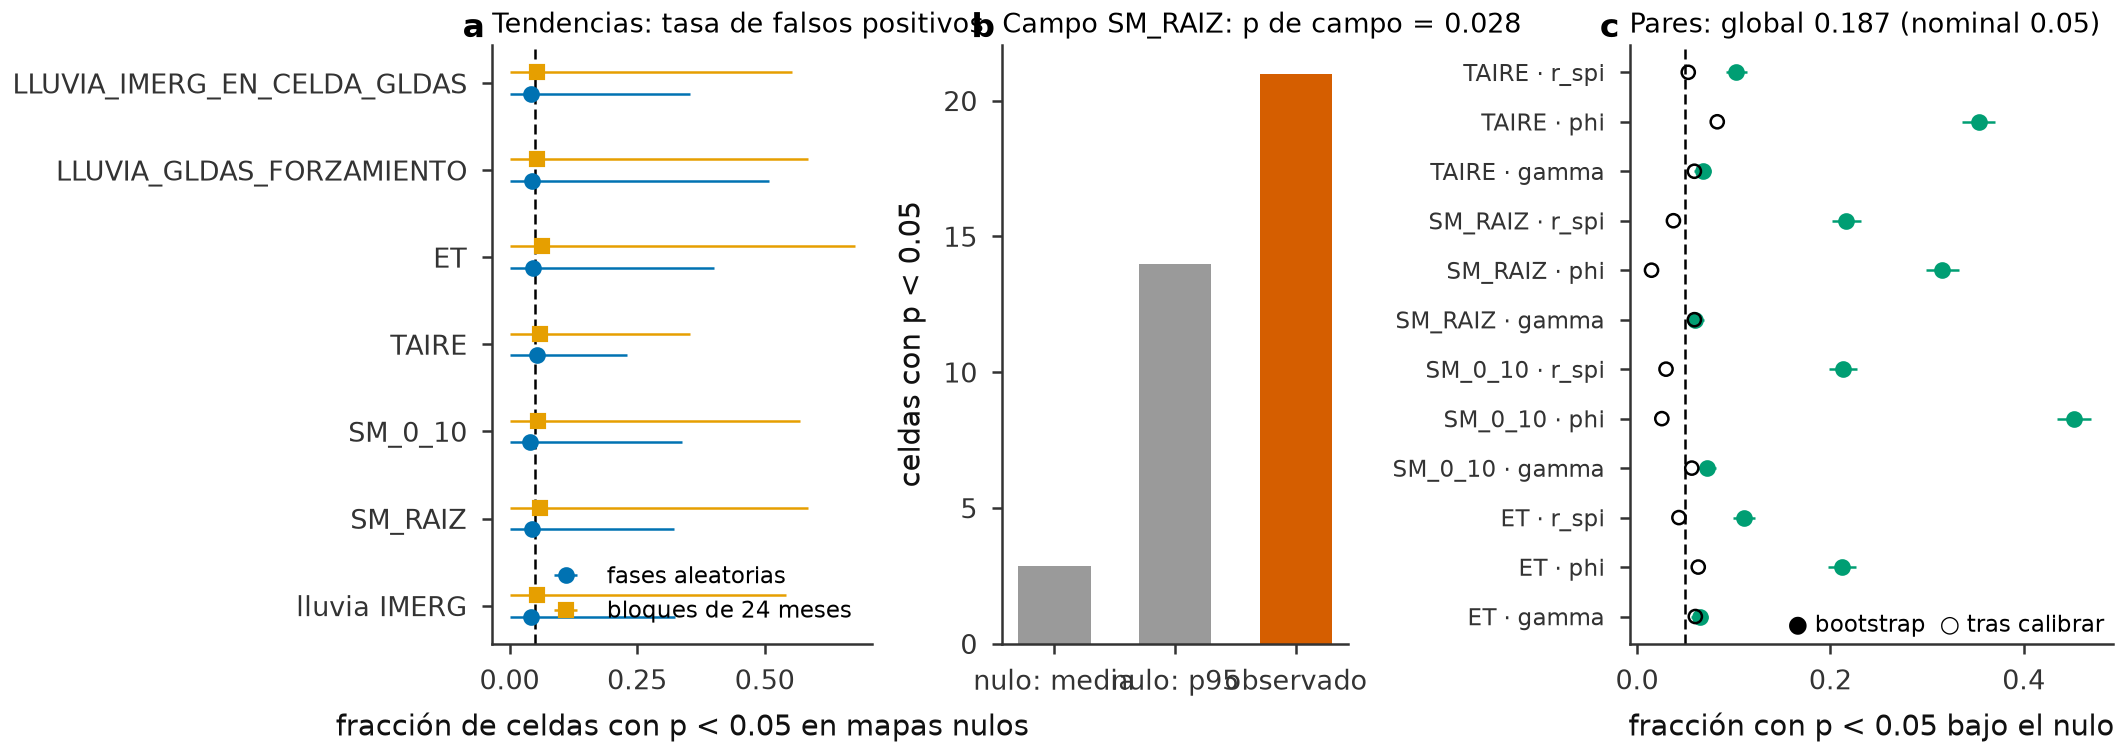

In [2]:
fig("fig08_calibracion_fpr")

## Tendencias: tasa nominal vs empírica

In [3]:
cal = json.loads((RES / "calibracion_tendencias.json").read_text(encoding="utf-8"))
pd.DataFrame({v: {"fases": c["fase"]["tasa_empirica_p05"], "bloques": c["bloques"]["tasa_empirica_p05"],
                  "p_campo": c["fase"]["p_campo"], "I_Moran": c["moran_I_pendiente"],
                  "q05_nominal": c["celdas_q05_nominal"], "q05_calibrado": c["celdas_q05_calibrado"]} for v, c in cal.items()}).T

,fases,bloques,p_campo,I_Moran,q05_nominal,q05_calibrado
PRECIP_IMERG_0.1,0.041851,0.054803,0.326673,0.854855,0.0,0.0
SM_RAIZ,0.044031,0.060554,0.027972,0.425291,2.0,8.0
SM_0_10,0.040231,0.056631,0.083916,0.386072,0.0,0.0
TAIRE,0.054646,0.059723,0.079920,0.249531,6.0,6.0
ET,0.045723,0.062815,1.000000,0.232831,0.0,0.0
LLUVIA_GLDAS_FORZAMIENTO,0.043108,0.053123,1.000000,0.411656,0.0,0.0
LLUVIA_IMERG_EN_CELDA_GLDAS,0.041985,0.054523,1.000000,0.632540,0.0,0.0


## Pares: inflación del error estándar

La prueba de pares con bootstrap de bloques de 12 meses rechaza más de lo nominal bajo el nulo. Se corrige dividiendo |Δ/EE| por el factor de inflación σ medido en el nulo.

In [4]:
pd.read_csv(RES / "calibracion_pares_resumen.csv")

,respuesta,metrica,n,tasa_empirica_p05,factor_inflacion_EE,tasa_p05_tras_calibrar,z_abs_critico_95
0,ET,gamma,3000,0.065000,1.02003,0.060333,2.09931
1,ET,phi,3000,0.212333,1.53034,0.063333,3.25891
2,ET,r_spi,3000,0.110667,1.25957,0.043333,2.40126
3,SM_0_10,gamma,3000,0.072000,1.06603,0.056667,2.14034
4,SM_0_10,phi,3000,0.452333,2.60341,0.025667,4.53967
5,SM_0_10,r_spi,3000,0.213000,1.63223,0.030000,2.90125
6,SM_RAIZ,gamma,3000,0.060333,1.01574,0.059333,2.09504
7,SM_RAIZ,phi,3000,0.316000,2.06611,0.015000,3.33247
8,SM_RAIZ,r_spi,3000,0.216667,1.64060,0.037667,3.05462
9,TAIRE,gamma,3000,0.068000,1.04458,0.059333,2.15458


## Santo Domingo, 18 de noviembre de 2023

El pluviómetro de ONAMET en Arroyo Hondo Viejo reportó 431 mm en 24 h (preliminar). Una celda IMERG promedia ~110 km²: el producto en rejilla suaviza el extremo. Un evento no es una tendencia. Los valores IMERG son cálculo nuestro.

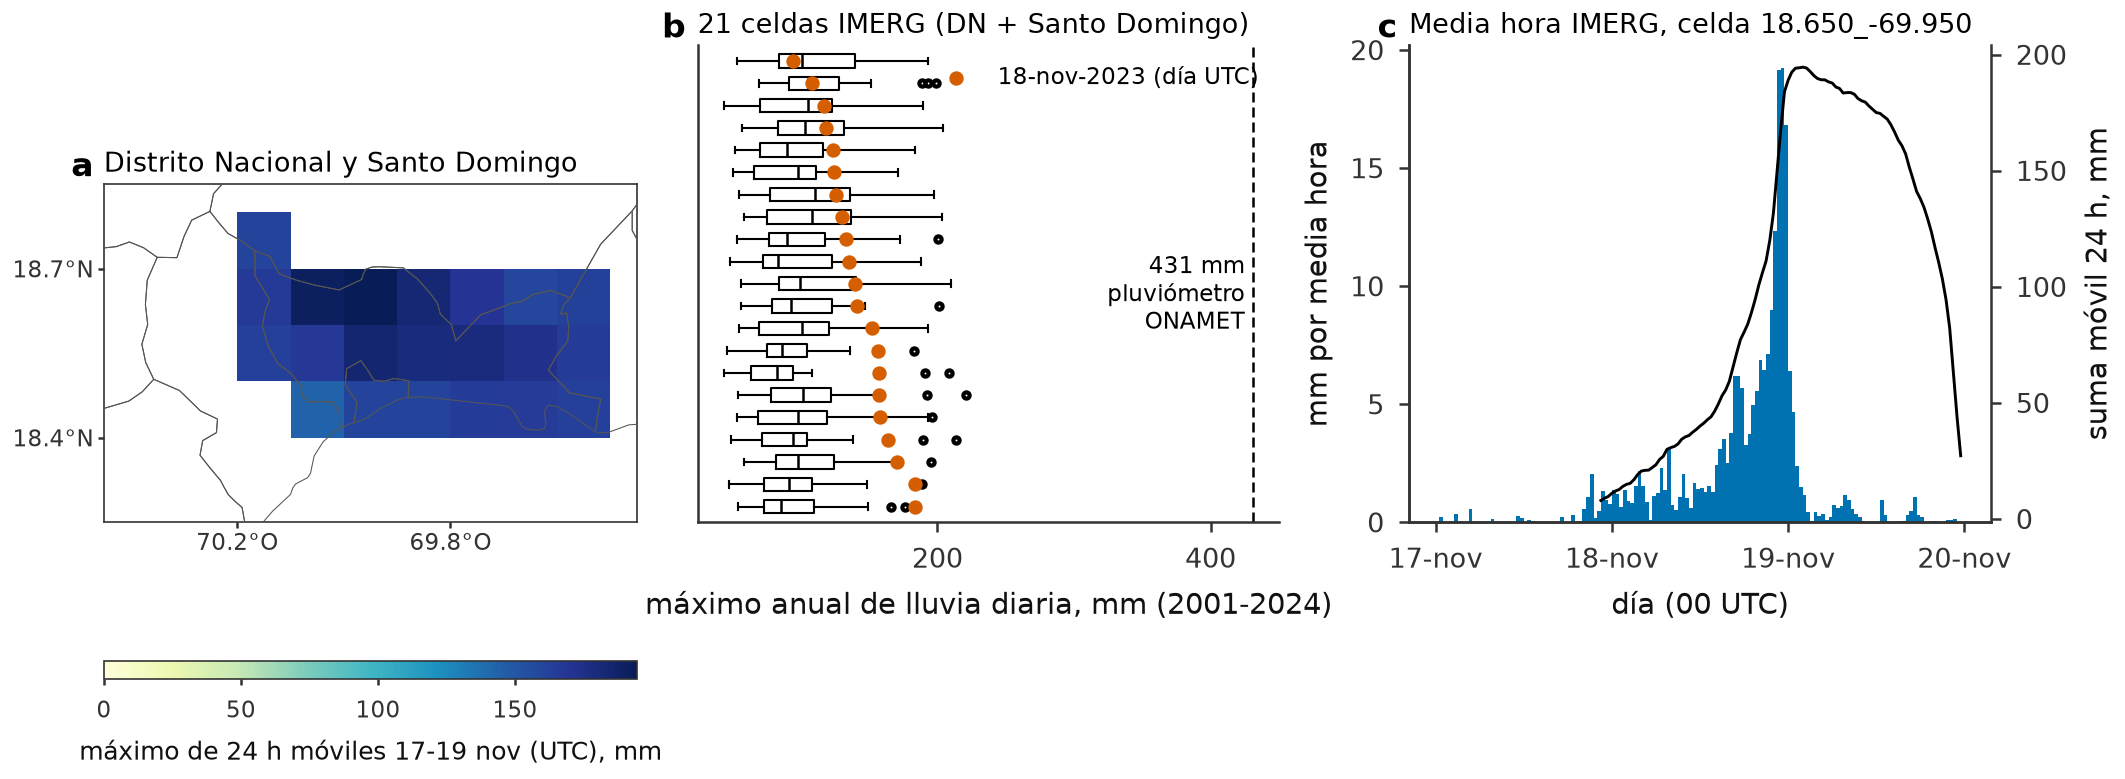

In [5]:
fig("fig09_santo_domingo_2023")

In [6]:
print(json.dumps(json.loads((RES / "evento_santo_domingo_2023-11-18.json").read_text(encoding="utf-8")), ensure_ascii=False, indent=1)[:2500])
pd.read_csv(RES / "evento_santo_domingo_por_celda.csv").head(10)

{
 "fecha": "2023-11-18",
 "provincias": [
  "DO-01",
  "DO-32"
 ],
 "celdas_imerg_que_cubren": 21,
 "afirmacion_contrastada": "431 mm en 24 h el sábado 18-nov-2023 en la estación de ONAMET Arroyo Hondo Viejo (dato preliminar; 474 mm acumulados desde el jueves). Es un pluviómetro (un punto); NASA no publicó una magnitud IMERG para este evento: todo valor IMERG aquí es cálculo nuestro sobre IMERG Final V07.",
 "nota": "IMERG diario = día UTC (00-24 UTC = 20:00 del día anterior a 20:00 hora local). Una celda IMERG de 0.1° (~10.5 × 10.6 km) promedia el aguacero sobre ~110 km²; un pluviómetro mide un punto. Un solo evento no es una tendencia.",
 "celda_max": "18.650_-69.950",
 "celda_max_detalle": {
  "fecha": "2023-11-18",
  "valor_mm": 183.92,
  "suma_3_dias_mm": 220.665,
  "n_dias": 8766,
  "puesto_entre_todos_los_dias": 1,
  "percentil_entre_todos_los_dias": 99.9886,
  "n_anios": 24,
  "puesto_entre_maximos_anuales": 1,
  "periodo_retorno_empirico_anios": 25.0,
  "puesto_3dias_entre_ma

,celda,mm_dia_utc_evento,mm_dia_utc_siguiente,mm_2_dias,puesto_entre_todos_los_dias,puesto_entre_maximos_anuales,periodo_retorno_empirico_anios,maximo_anual_mediana_mm,maximo_registro_mm,fecha_maximo_registro,n_dias
0,18.650_-69.950,183.920,27.140,211.060,1,1,25.00000,85.7550,183.920,2023-11-18,8766
1,18.650_-70.050,183.760,25.415,209.175,3,3,8.33333,91.4825,188.790,2007-10-29,8766
2,18.550_-69.950,170.180,30.915,201.095,2,2,12.50000,98.2150,195.540,2020-08-23,8766
3,18.650_-70.150,164.090,20.265,184.355,3,3,8.33333,93.9000,213.785,2007-10-29,8766
4,18.550_-70.050,157.810,29.175,186.985,4,3,8.33333,97.7475,195.805,2020-08-23,8766
5,18.550_-70.150,157.035,23.270,180.305,4,3,8.33333,101.8280,220.585,2007-10-29,8766
6,18.750_-70.150,156.965,18.575,175.540,3,3,8.33333,82.4600,208.615,2007-10-29,8766
7,18.650_-69.850,156.735,40.810,197.545,2,2,12.50000,85.9200,183.115,2020-08-23,8766
8,18.550_-69.850,152.080,43.500,195.580,2,2,12.50000,100.7420,193.070,2020-08-23,8766
9,18.550_-69.750,141.150,53.365,194.515,3,3,8.33333,92.9375,201.305,2020-08-23,8766


## Límites que no se pueden corregir con estadística

- GLDAS es un modelo forzado con GPCP y sin asimilación de suelo: describe el suelo del modelo, no mediciones.
- 24 años no separan cambio de largo plazo de variabilidad decenal.
- Celdas vecinas comparten lluvia y forzamiento: dos pares que comparten celda no son dos hallazgos.
- Ninguna asociación aquí es causa.
- NDVI/NPP (AppEEARS) y SMAP no entraron en esta corrida; GRACE-FO (~3°) solo serviría como contexto nacional.